# Fashion-MNIST Clustering Before and After PCA

We compare KMeans clustering on the original 784 pixel features and on two PCA components to see how dimensionality reduction affects the results.

In [62]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from sklearn.metrics import silhouette_score, adjusted_rand_score

import kagglehub
import os

In [63]:
path = kagglehub.dataset_download("zalando-research/fashionmnist")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fashionmnist' dataset.
Path to dataset files: /kaggle/input/fashionmnist


In [64]:
os.listdir(path)

['t10k-labels-idx1-ubyte',
 't10k-images-idx3-ubyte',
 'fashion-mnist_test.csv',
 'fashion-mnist_train.csv',
 'train-labels-idx1-ubyte',
 'train-images-idx3-ubyte']

In [65]:
csv_path = os.path.join(path, "fashion-mnist_train.csv")
df = pd.read_csv(csv_path)
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Each row represents one clothing image. The 784 pixel columns describe a 28 × 28 image, and the label gives its clothing category.

In [66]:
df.shape

(60000, 785)

In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, label to pixel784
dtypes: int64(785)
memory usage: 359.3 MB


In [68]:
df.isnull().sum()

,0
label,0
pixel1,0
pixel2,0
pixel3,0
pixel4,0
...,...
pixel780,0
pixel781,0
pixel782,0
pixel783,0


In [69]:
df.isnull().sum().sum()

np.int64(0)

In [70]:
df.duplicated().sum()

np.int64(43)

In [71]:
df = df.drop_duplicates()

In [72]:
df.duplicated().sum()

np.int64(0)

In [73]:
df["label"].value_counts().sort_index()

,count
label,
0,5998
1,5996
2,5988
3,5997
4,5995
5,6000
6,5989
7,5996
8,6000


to check the imbalance

In [74]:
pixels = df.drop(columns=["label"])

print("Minimum pixel value:", pixels.min().min())
print("Maximum pixel value:", pixels.max().max())

Minimum pixel value: 0
Maximum pixel value: 255


The dataset contained 60,000 images with no missing values. We removed 43 duplicate rows, leaving 59,957 images. Pixel values ranged from 0 to 255.

In [75]:
data = df.sample(n=10000, random_state=42).reset_index(drop=True)

In [76]:
X = data.drop(columns=["label"])
y = data["label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 784)
y shape: (10000,)


We selected the same random sample of 10,000 images for both experiments. We used the pixel values for clustering and kept the true labels for evaluation.

##EDA

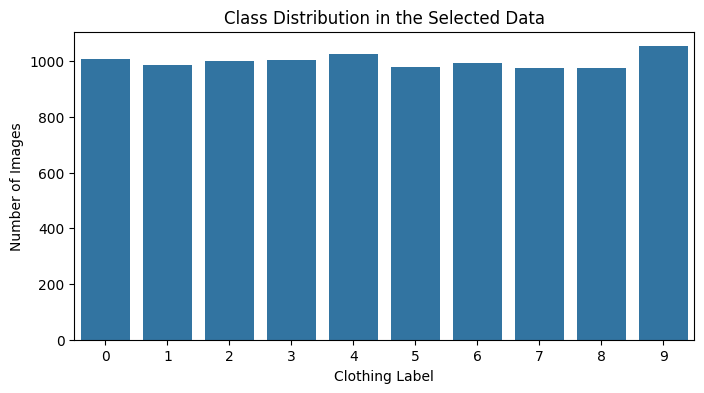

In [77]:
plt.figure(figsize=(8, 4))

sns.countplot(data=data, x="label")

plt.title("Class Distribution in the Selected Data")
plt.xlabel("Clothing Label")
plt.ylabel("Number of Images")

plt.show()

The ten clothing categories are fairly balanced in our sample, with about 1,000 images per category.

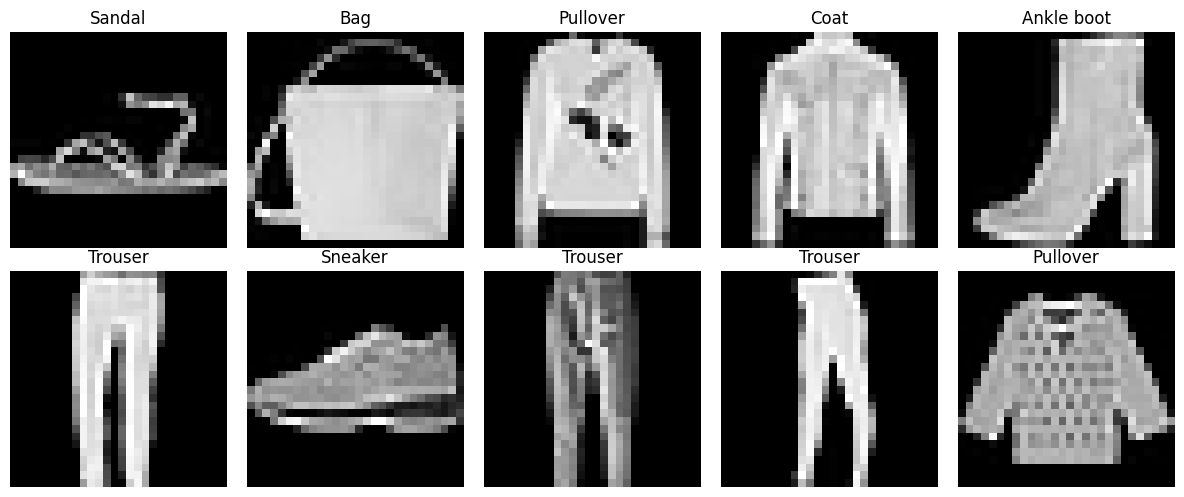

In [78]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = X.iloc[i].to_numpy().reshape(28, 28)
    label = int(y.iloc[i])

    ax.imshow(image, cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

We reshaped the first ten sampled images to 28 × 28 pixels to view the clothing items and their labels.

In [79]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(10000, 784)


We used StandardScaler to put the pixel features on a common scale before applying KMeans and PCA.

In [80]:
kmeans_before = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

clusters_before = kmeans_before.fit_predict(X_scaled)

In [81]:
pd.Series(clusters_before).value_counts().sort_index()

,count
0,1805
1,1471
2,1231
3,1517
4,421
5,1292
6,836
7,360
8,634
9,433


We grouped the images into ten clusters using all 784 standardized pixel features. The table shows the number of images assigned to each cluster.

In [82]:
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

print(X_pca.shape)

(10000, 2)


PCA reduced the 784 pixel features to two components, so we could plot each image as a point on a 2D graph.

In [83]:
kmeans_after = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

clusters_after = kmeans_after.fit_predict(X_pca)

We ran KMeans again on the two PCA components using the same settings to compare the two representations.

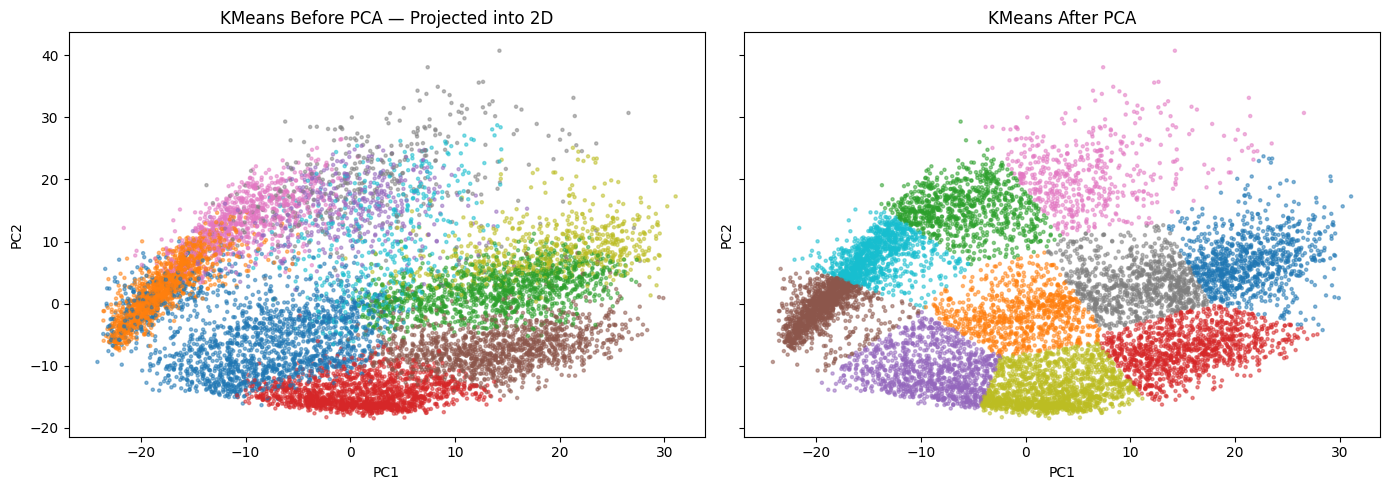

In [84]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    sharey=True
)

axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters_before,
    cmap="tab10",
    s=5,
    alpha=0.5
)

axes[0].set_title("KMeans Before PCA — Projected into 2D")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters_after,
    cmap="tab10",
    s=5,
    alpha=0.5
)

axes[1].set_title("KMeans After PCA")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

Both plots show the same images on PC1 and PC2. On the left, the colors show clusters formed using 784 features. On the right, the colors show clusters formed using only PC1 and PC2, so their boundaries appear clearer in this view.

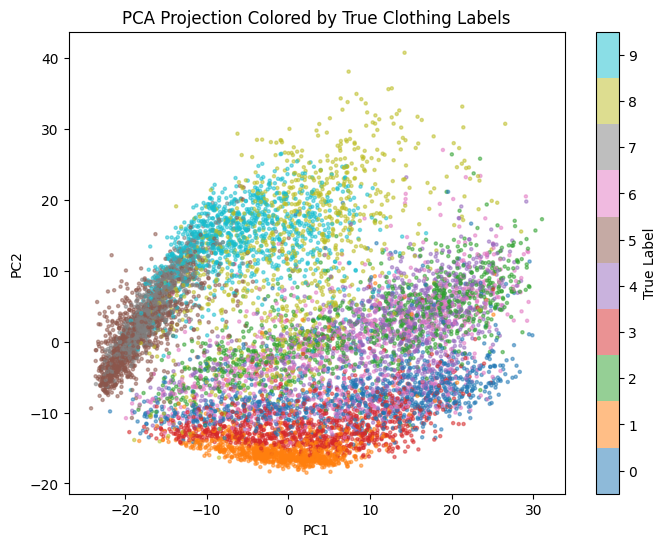

In [85]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="tab10",
    s=5,
    alpha=0.5,
    vmin=-0.5,
    vmax=9.5
)

plt.colorbar(scatter, ticks=range(10), label="True Label")

plt.title("PCA Projection Colored by True Clothing Labels")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.show()

Each color represents a true clothing category. Trousers form a visible group near the bottom, while several other categories overlap in the two-dimensional view.

In [86]:
silhouette_before = silhouette_score(
    X_scaled,
    clusters_before,
    sample_size=2000,
    random_state=42
)

silhouette_after = silhouette_score(
    X_pca,
    clusters_after,
    sample_size=2000,
    random_state=42
)

ari_before = adjusted_rand_score(y, clusters_before)
ari_after = adjusted_rand_score(y, clusters_after)

In [87]:
results = pd.DataFrame({
    "Approach": ["Before PCA", "After PCA"],
    "Number of Features": [X_scaled.shape[1], X_pca.shape[1]],
    "Silhouette Score": [silhouette_before, silhouette_after],
    "ARI": [ari_before, ari_after]
})

results.round(3)

,Approach,Number of Features,Silhouette Score,ARI
0,Before PCA,784,0.127,0.322
1,After PCA,2,0.404,0.261


The Silhouette Score increased from 0.127 to 0.404, while ARI decreased from 0.322 to 0.261. The clusters were more separated in the two-dimensional space, but they agreed less with the true clothing categories.


Cluster 0
Number of images: 1805


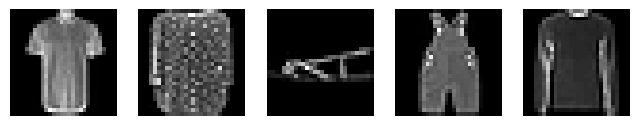


Cluster 1
Number of images: 1471


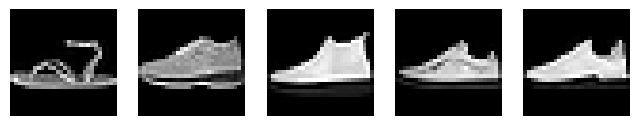


Cluster 2
Number of images: 1231


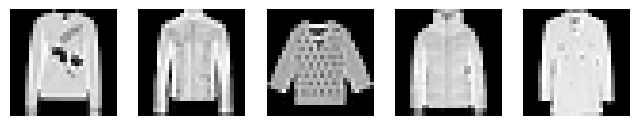


Cluster 3
Number of images: 1517


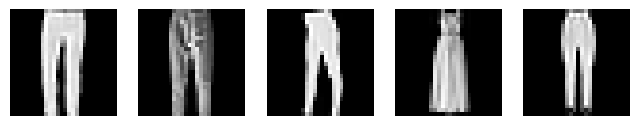


Cluster 4
Number of images: 421


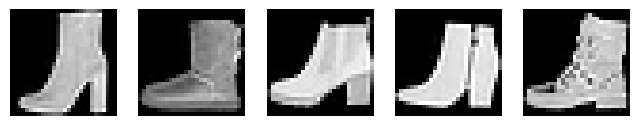


Cluster 5
Number of images: 1292


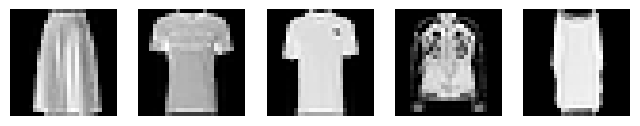


Cluster 6
Number of images: 836


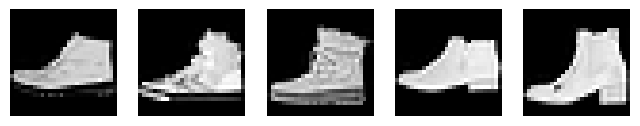


Cluster 7
Number of images: 360


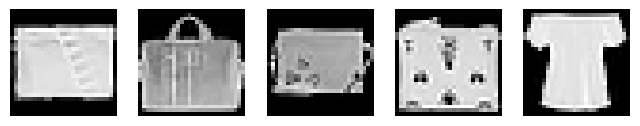


Cluster 8
Number of images: 634


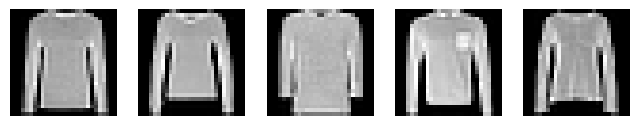


Cluster 9
Number of images: 433


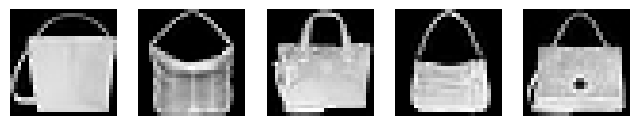

In [88]:
for cluster_id in range(10):

    idx = np.where(clusters_before == cluster_id)[0]

    print(f"\nCluster {cluster_id}")
    print("Number of images:", len(idx))

    fig, axes = plt.subplots(1, 5, figsize=(8, 2))

    for j, ax in enumerate(axes):
        if j < len(idx):
            image = X.iloc[idx[j]].to_numpy().reshape(28, 28)
            ax.imshow(image, cmap="gray")

        ax.axis("off")

    plt.show()

Before PCA, the five examples shown from Cluster 9 were all bags, and the examples from Cluster 4 were boots.


Cluster 0
Number of images: 926


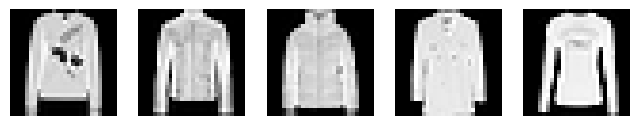


Cluster 1
Number of images: 839


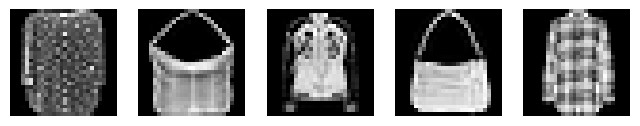


Cluster 2
Number of images: 909


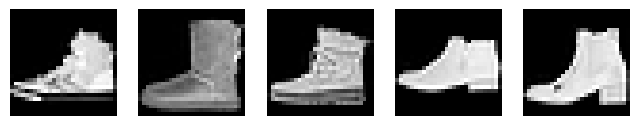


Cluster 3
Number of images: 1108


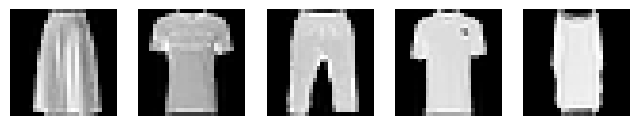


Cluster 4
Number of images: 1055


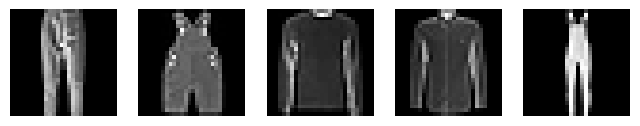


Cluster 5
Number of images: 1223


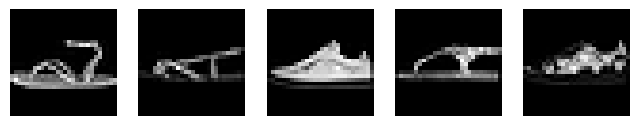


Cluster 6
Number of images: 529


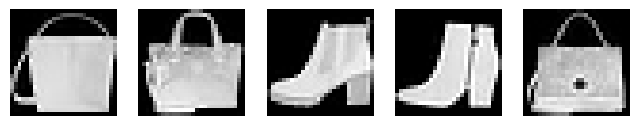


Cluster 7
Number of images: 900


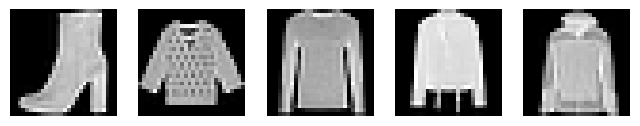


Cluster 8
Number of images: 1473


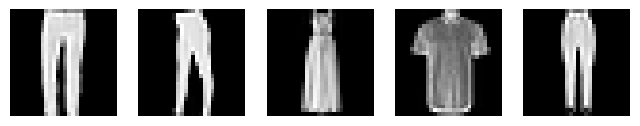


Cluster 9
Number of images: 1038


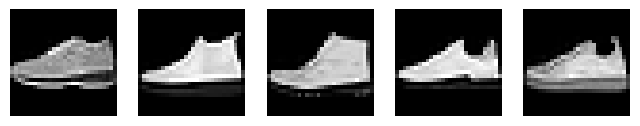

In [89]:
for cluster_id in range(10):

    idx = np.where(clusters_after == cluster_id)[0]

    print(f"\nCluster {cluster_id}")
    print("Number of images:", len(idx))

    fig, axes = plt.subplots(1, 5, figsize=(8, 2))

    for j, ax in enumerate(axes):
        if j < len(idx):
            image = X.iloc[idx[j]].to_numpy().reshape(28, 28)
            ax.imshow(image, cmap="gray")

        ax.axis("off")

    plt.show()

After PCA, the examples from Cluster 6 included both bags and boots. This shows how different clothing categories can appear in the same cluster.

## Key Insights

- The clusters looked clearer after PCA because KMeans used the same two components shown in the plot.
- The Silhouette Score increased from 0.127 to 0.404. This shows clearer separation in the 2D space.
- The ARI decreased from 0.322 to 0.261. This suggests that reducing the images to two components may have removed some details that help distinguish clothing categories.
- In our experiment, PCA helped us visualize the clusters, while KMeans on all 784 features grouped the images more closely by their true clothing categories.

## Bonus 1: Trying Different PCA Components

We tested different numbers of PCA components to see how dimensionality reduction affects KMeans clustering results.

We tested 2, 10, 30, and 50 PCA components. For each number, we applied KMeans with ten clusters and calculated the Silhouette Score, ARI, and explained variance.

In [90]:
components_list = [2, 10, 30, 50]

pca_results = []

for n in components_list:

    pca = PCA(n_components=n, random_state=42)
    X_pca_temp = pca.fit_transform(X_scaled)

    kmeans = KMeans(
        n_clusters=10,
        random_state=42,
        n_init=10
    )

    clusters = kmeans.fit_predict(X_pca_temp)

    silhouette = silhouette_score(
        X_pca_temp,
        clusters,
        sample_size=2000,
        random_state=42
    )

    ari = adjusted_rand_score(y, clusters)

    explained_variance = pca.explained_variance_ratio_.sum()

    pca_results.append({
        "PCA Components": n,
        "Silhouette Score": silhouette,
        "ARI": ari,
        "Explained Variance": explained_variance
    })

pca_comparison = pd.DataFrame(pca_results)

pca_comparison.round(3)

,PCA Components,Silhouette Score,ARI,Explained Variance
0,2,0.404,0.261,0.365
1,10,0.291,0.341,0.624
2,30,0.211,0.340,0.746
3,50,0.186,0.347,0.802


We plotted the Silhouette Score and ARI for each number of PCA components to compare how the number of components affected the clustering results.

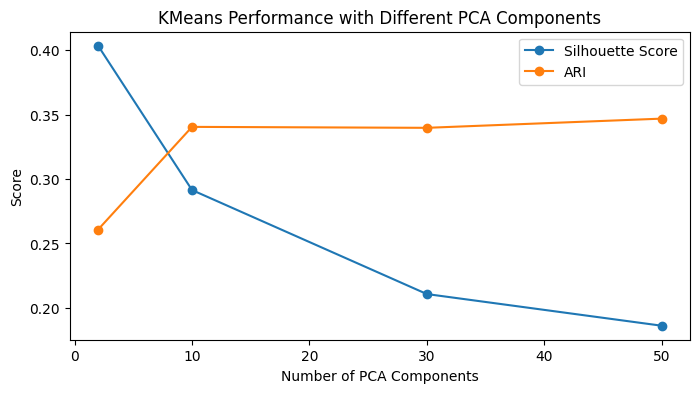

In [91]:
plt.figure(figsize=(8, 4))

plt.plot(
    pca_comparison["PCA Components"],
    pca_comparison["Silhouette Score"],
    marker="o",
    label="Silhouette Score"
)

plt.plot(
    pca_comparison["PCA Components"],
    pca_comparison["ARI"],
    marker="o",
    label="ARI"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Score")
plt.title("KMeans Performance with Different PCA Components")
plt.legend()
plt.show()

## Bonus 2: Comparing KMeans with DBSCAN

We used DBSCAN as another clustering algorithm to compare its results with KMeans.

We imported DBSCAN, a density-based clustering algorithm, to compare it with KMeans.

In [92]:
from sklearn.cluster import DBSCAN

We reduced the standardized pixel features to ten PCA components before applying DBSCAN. This gives both clustering algorithms a lower-dimensional representation of the images.

In [93]:
pca_dbscan = PCA(n_components=10, random_state=42)

X_pca_dbscan = pca_dbscan.fit_transform(X_scaled)

We applied DBSCAN to the ten PCA components. The eps parameter controls the neighborhood distance, while min_samples sets the minimum number of points needed to form a dense region.

In [94]:
dbscan = DBSCAN(
    eps=3,
    min_samples=10
)

clusters_dbscan = dbscan.fit_predict(X_pca_dbscan)

We counted the clusters found by DBSCAN and the images classified as noise. The label -1 represents images that DBSCAN did not assign to a cluster.

In [95]:
unique_clusters = set(clusters_dbscan)

n_clusters = len(unique_clusters - {-1})

n_noise = list(clusters_dbscan).count(-1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

Number of clusters: 19
Number of noise points: 7240


We evaluated DBSCAN using ARI and Silhouette Score. The Silhouette Score is calculated only for images that were not classified as noise, when the remaining data contains more than one cluster.

In [96]:
ari_dbscan = adjusted_rand_score(y, clusters_dbscan)

non_noise = clusters_dbscan != -1

if 1 < len(set(clusters_dbscan[non_noise])) < non_noise.sum():

    silhouette_dbscan = silhouette_score(
        X_pca_dbscan[non_noise],
        clusters_dbscan[non_noise],
        sample_size=min(2000, non_noise.sum()),
        random_state=42
    )

else:
    silhouette_dbscan = np.nan

print("DBSCAN ARI:", ari_dbscan)
print("DBSCAN Silhouette:", silhouette_dbscan)

DBSCAN ARI: 0.07404078605418525
DBSCAN Silhouette: 0.008995563971254325


We created a table to compare DBSCAN with the KMeans results from the main experiment. This gives an initial comparison, although the two algorithms used different PCA representations.

In [97]:
algorithm_comparison = pd.DataFrame({
    "Algorithm": ["KMeans", "DBSCAN"],
    "Number of Clusters": [
        len(set(clusters_after)),
        n_clusters
    ],
    "ARI": [
        ari_after,
        ari_dbscan
    ],
    "Silhouette Score": [
        silhouette_after,
        silhouette_dbscan
    ]
})

algorithm_comparison.round(3)

,Algorithm,Number of Clusters,ARI,Silhouette Score
0,KMeans,10,0.261,0.404
1,DBSCAN,19,0.074,0.009


We applied KMeans again using the same ten PCA components used for DBSCAN. This makes the comparison between the two algorithms fairer.

In [98]:
kmeans_10 = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

clusters_kmeans_10 = kmeans_10.fit_predict(X_pca_dbscan)

ari_kmeans_10 = adjusted_rand_score(y, clusters_kmeans_10)

silhouette_kmeans_10 = silhouette_score(
    X_pca_dbscan,
    clusters_kmeans_10,
    sample_size=2000,
    random_state=42
)

We created a final comparison table using KMeans and DBSCAN on the same ten-component PCA representation. The table shows the number of clusters, ARI, and Silhouette Score for each algorithm.

In [99]:
algorithm_comparison = pd.DataFrame({
    "Algorithm": ["KMeans", "DBSCAN"],
    "Number of Clusters": [10, n_clusters],
    "ARI": [ari_kmeans_10, ari_dbscan],
    "Silhouette Score": [
        silhouette_kmeans_10,
        silhouette_dbscan
    ]
})

algorithm_comparison.round(3)

,Algorithm,Number of Clusters,ARI,Silhouette Score
0,KMeans,10,0.341,0.291
1,DBSCAN,19,0.074,0.009


## Bonus Insights

### Different PCA Components

We tested different numbers of PCA components to see how they affect clustering performance. The results showed how changing the number of components affected the Silhouette Score and ARI.

### KMeans vs DBSCAN

We compared KMeans and DBSCAN using the same PCA representation. DBSCAN identified dense groups and noise points, while KMeans assigned every image to one of ten clusters.

The results helped us understand the differences between centroid-based and density-based clustering.